# Test-Set Comparison: Random vs Scaffold Splits
This notebook evaluates six models on their **own unseen test sets**:
- 3 models trained with **random split**
- 3 models trained with **scaffold split**

We keep test sets strictly **unseen** by recreating each split with `get_split` and evaluating only its corresponding test partition.

Sections:
1. Load splits and build test datasets
2. Load model weights
3. Evaluate and compare metrics
4. Visual comparisons
5. Lightweight XAI-style analyses (residual patterns and molecule examples)

In [1]:
import os
import numpy as np
import pandas as pd
import torch
from torch import nn
import torch.nn.functional as F
from tqdm import tqdm

import matplotlib.pyplot as plt
import seaborn as sns

from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit.Chem import Draw

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import helpers as hp

from tdc.single_pred import ADME
from torch_geometric.data import Data, InMemoryDataset
from torch_geometric.loader import DataLoader as PyGDataLoader
from torch_geometric.nn import GCNConv, GINConv, global_mean_pool
from ogb.utils import smiles2graph as smiles2graph_ogb
from ogb.graphproppred.mol_encoder import AtomEncoder

In [2]:
# Configuration
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
TARGET_COL = 'Y'
SMILES_COL = 'Canonical_SMILES'

MODEL_DIRS = {
    'random': 'saved_models_randomsplit',
    'scaffold': 'saved_models_scaffoldsplit',
}

MODEL_FILES = {
    'gcn_scratch': 'gcn_scratch_best.pt',
    'pyg_gcn': 'pyg_gcn_best.pt',
    'pyg_gin': 'pyg_gin_best.pt',
}

PYG_ROOTS = {
    'random': './lipophilicity_pyg_random_eval',
    'scaffold': './lipophilicity_pyg_scaffold_eval',
}

print('Device:', DEVICE)

Device: cpu


## Load splits (random + scaffold) and rebuild clean SMILES

In [3]:
def get_split_clean(split_type):
    data = ADME(name='Lipophilicity_AstraZeneca')
    split = data.get_split(method=split_type)

    split['train']['_source'] = 'train'
    split['valid']['_source'] = 'valid'
    split['test']['_source'] = 'test'

    combined = pd.concat([split['train'], split['valid'], split['test']], ignore_index=True)
    combined['Mol'] = combined.Drug.apply(Chem.MolFromSmiles)
    combined = combined.dropna(subset=['Mol'])
    combined[SMILES_COL] = combined.Mol.apply(lambda x: Chem.MolToSmiles(x, canonical=True))
    combined.drop_duplicates(subset=SMILES_COL, keep='first', inplace=True)

    split['train'] = combined[combined['_source'] == 'train'].drop(columns=['_source'])
    split['valid'] = combined[combined['_source'] == 'valid'].drop(columns=['_source'])
    split['test'] = combined[combined['_source'] == 'test'].drop(columns=['_source'])

    return split, combined

split_random, combined_random = get_split_clean('random')
split_scaffold, combined_scaffold = get_split_clean('scaffold')

print('Random test size:', len(split_random['test']))
print('Scaffold test size:', len(split_scaffold['test']))

Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
100%|██████████| 4200/4200 [00:01<00:00, 4042.89it/s]


Random test size: 840
Scaffold test size: 840


In [4]:
def report_overlap(split, label):
    train_smiles = set(split['train'][SMILES_COL])
    valid_smiles = set(split['valid'][SMILES_COL])
    test_smiles = set(split['test'][SMILES_COL])

    print(f'[{label}] unique counts - train: {len(train_smiles)}, valid: {len(valid_smiles)}, test: {len(test_smiles)}')
    print(f'[{label}] overlaps - train∩valid: {len(train_smiles & valid_smiles)}')
    print(f'[{label}] overlaps - train∩test: {len(train_smiles & test_smiles)}')
    print(f'[{label}] overlaps - valid∩test: {len(valid_smiles & test_smiles)}')
    print('')

report_overlap(split_random, 'random')
report_overlap(split_scaffold, 'scaffold')

[random] unique counts - train: 2940, valid: 420, test: 840
[random] overlaps - train∩valid: 0
[random] overlaps - train∩test: 0
[random] overlaps - valid∩test: 0

[scaffold] unique counts - train: 2940, valid: 420, test: 840
[scaffold] overlaps - train∩valid: 0
[scaffold] overlaps - train∩test: 0
[scaffold] overlaps - valid∩test: 0



## Build datasets and loaders

In [5]:
class LipophilicityGraphData(InMemoryDataset):
    def __init__(self, root, df, split_name, smiles_col=SMILES_COL, target_col=TARGET_COL):
        self.df = df[[smiles_col, target_col]].reset_index(drop=True).copy()
        self.smiles_col = smiles_col
        self.target_col = target_col
        self.split_name = split_name
        super().__init__(root)
        self.data, self.slices = torch.load(self.processed_paths[0], weights_only=False)

    @property
    def raw_file_names(self):
        return []

    @property
    def processed_file_names(self):
        return [f'{self.split_name}.pt']

    def download(self):
        pass

    def process(self):
        data_list = []
        for _, row in tqdm(self.df.iterrows(), total=len(self.df), desc=f'Featurising {self.split_name}'):
            smi = row[self.smiles_col]
            y_val = float(row[self.target_col])
            g = smiles2graph_ogb(smi)
            data_list.append(
                Data(
                    x=torch.tensor(g['node_feat'], dtype=torch.long),
                    edge_index=torch.tensor(g['edge_index'], dtype=torch.long),
                    edge_attr=torch.tensor(g['edge_feat'], dtype=torch.long),
                    y=torch.tensor([y_val], dtype=torch.float),
                ),
            )
        data, slices = self.collate(data_list)
        torch.save((data, slices), self.processed_paths[0])

def build_loaders(split, split_type):
    test_df = split['test']

    # Scratch dataset
    test_ds = hp.GNNDataset(test_df[SMILES_COL], test_df[TARGET_COL])
    test_loader = hp.DataLoader(test_ds, batch_size=1, shuffle=False)

    root = PYG_ROOTS[split_type]
    test_pyg = LipophilicityGraphData(root, test_df, 'test')
    test_pyg_loader = PyGDataLoader(test_pyg, batch_size=64, shuffle=False)

    return test_loader, test_pyg_loader, test_df

test_loader_random, test_pyg_loader_random, test_df_random = build_loaders(split_random, 'random')
test_loader_scaffold, test_pyg_loader_scaffold, test_df_scaffold = build_loaders(split_scaffold, 'scaffold')

print('Random test batches (scratch):', len(test_loader_random))
print('Random test batches (pyg):', len(test_pyg_loader_random))
print('Scaffold test batches (scratch):', len(test_loader_scaffold))
print('Scaffold test batches (pyg):', len(test_pyg_loader_scaffold))

Random test batches (scratch): 840
Random test batches (pyg): 14
Scaffold test batches (scratch): 840
Scaffold test batches (pyg): 14


## Model definitions (matching training)

In [6]:
class GCNModelDropout(nn.Module):
    def __init__(self, in_features, hidden, out_features=1, n_layers=2, dropout=0.2, pool_fn=torch.mean):
        super().__init__()
        self.convs = nn.ModuleList()
        self.convs.append(hp.GCNLayer(in_features, hidden))
        for _ in range(n_layers - 1):
            self.convs.append(hp.GCNLayer(hidden, hidden))
        self.dropout = nn.Dropout(dropout)
        self.readout = nn.Sequential(
            nn.Linear(hidden, hidden // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden // 2, out_features),
        )
        self.pool_fn = pool_fn

    def forward(self, X, A):
        h = X
        for conv in self.convs:
            h = conv(h, A)
            h = self.dropout(h)
        h_graph = self.pool_fn(h, dim=0)
        return self.readout(h_graph)

class LightningGCN(nn.Module):
    def __init__(self, hidden=128, dropout=0.2):
        super().__init__()
        self.atom_emb = AtomEncoder(emb_dim=hidden)
        self.conv1 = GCNConv(hidden, hidden)
        self.conv2 = GCNConv(hidden, hidden)
        self.dropout = dropout
        self.readout = nn.Sequential(
            nn.Linear(hidden, hidden // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden // 2, 1),
        )

    def forward(self, x, edge_index, batch):
        x = self.atom_emb(x)
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = F.relu(self.conv2(x, edge_index))
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = global_mean_pool(x, batch)
        return self.readout(x)

class LightningGIN(nn.Module):
    def __init__(self, hidden=128, dropout=0.2):
        super().__init__()
        self.atom_emb = AtomEncoder(emb_dim=hidden)
        self.mlp1 = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, hidden))
        self.mlp2 = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, hidden))
        self.conv1 = GINConv(self.mlp1)
        self.conv2 = GINConv(self.mlp2)
        self.dropout = dropout
        self.readout = nn.Sequential(
            nn.Linear(hidden, hidden // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden // 2, 1),
        )

    def forward(self, x, edge_index, batch):
        x = self.atom_emb(x)
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = F.relu(self.conv2(x, edge_index))
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = global_mean_pool(x, batch)
        return self.readout(x)

## Evaluation helpers

In [7]:
def evaluate_scratch(model, loader):
    model.eval()
    preds = []
    trues = []
    with torch.no_grad():
        for X_b, A_b, y_b in loader:
            X_b, A_b, y_b = X_b.squeeze(0), A_b.squeeze(0), y_b.squeeze(0)
            y_hat = model(X_b, A_b).squeeze().cpu().numpy()
            preds.append(float(y_hat))
            trues.append(float(y_b.cpu().numpy()))
    return np.array(trues), np.array(preds)

def evaluate_pyg(model, loader):
    model.eval()
    preds = []
    trues = []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(DEVICE)
            y_hat = model(batch.x, batch.edge_index, batch.batch).squeeze(-1).cpu().numpy()
            y = batch.y.squeeze(-1).cpu().numpy()
            preds.extend(list(y_hat))
            trues.extend(list(y))
    return np.array(trues), np.array(preds)

def compute_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = float(np.sqrt(mse))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {'rmse': rmse, 'mae': mae, 'r2': r2}

## Load weights and evaluate on each split's **unseen test set**

In [8]:
def load_state_if_exists(model, path):
    if not os.path.exists(path):
        print('Missing:', path)
        return None
    state = torch.load(path, map_location='cpu')
    model.load_state_dict(state)
    return model

results = []
pred_store = {}

# Random split models
random_dir = MODEL_DIRS['random']

gcn_scratch_random = GCNModelDropout(in_features=54, hidden=128, out_features=1, n_layers=2, dropout=0.2)
gcn_scratch_random = load_state_if_exists(gcn_scratch_random, os.path.join(random_dir, MODEL_FILES['gcn_scratch']))
if gcn_scratch_random is not None:
    y_true, y_pred = evaluate_scratch(gcn_scratch_random, test_loader_random)
    results.append({'split': 'random', 'model': 'GCN scratch', **compute_metrics(y_true, y_pred)})
    pred_store[('random', 'GCN scratch')] = (y_true, y_pred, test_df_random)

pyg_gcn_random = LightningGCN(hidden=128, dropout=0.2).to(DEVICE)
pyg_gcn_random = load_state_if_exists(pyg_gcn_random, os.path.join(random_dir, MODEL_FILES['pyg_gcn']))
if pyg_gcn_random is not None:
    y_true, y_pred = evaluate_pyg(pyg_gcn_random, test_pyg_loader_random)
    results.append({'split': 'random', 'model': 'PyG GCN', **compute_metrics(y_true, y_pred)})
    pred_store[('random', 'PyG GCN')] = (y_true, y_pred, test_df_random)

pyg_gin_random = LightningGIN(hidden=128, dropout=0.2).to(DEVICE)
pyg_gin_random = load_state_if_exists(pyg_gin_random, os.path.join(random_dir, MODEL_FILES['pyg_gin']))
if pyg_gin_random is not None:
    y_true, y_pred = evaluate_pyg(pyg_gin_random, test_pyg_loader_random)
    results.append({'split': 'random', 'model': 'PyG GIN', **compute_metrics(y_true, y_pred)})
    pred_store[('random', 'PyG GIN')] = (y_true, y_pred, test_df_random)

# Scaffold split models
scaffold_dir = MODEL_DIRS['scaffold']

gcn_scratch_scaffold = GCNModelDropout(in_features=54, hidden=128, out_features=1, n_layers=2, dropout=0.2)
gcn_scratch_scaffold = load_state_if_exists(gcn_scratch_scaffold, os.path.join(scaffold_dir, MODEL_FILES['gcn_scratch']))
if gcn_scratch_scaffold is not None:
    y_true, y_pred = evaluate_scratch(gcn_scratch_scaffold, test_loader_scaffold)
    results.append({'split': 'scaffold', 'model': 'GCN scratch', **compute_metrics(y_true, y_pred)})
    pred_store[('scaffold', 'GCN scratch')] = (y_true, y_pred, test_df_scaffold)

pyg_gcn_scaffold = LightningGCN(hidden=128, dropout=0.2).to(DEVICE)
pyg_gcn_scaffold = load_state_if_exists(pyg_gcn_scaffold, os.path.join(scaffold_dir, MODEL_FILES['pyg_gcn']))
if pyg_gcn_scaffold is not None:
    y_true, y_pred = evaluate_pyg(pyg_gcn_scaffold, test_pyg_loader_scaffold)
    results.append({'split': 'scaffold', 'model': 'PyG GCN', **compute_metrics(y_true, y_pred)})
    pred_store[('scaffold', 'PyG GCN')] = (y_true, y_pred, test_df_scaffold)

pyg_gin_scaffold = LightningGIN(hidden=128, dropout=0.2).to(DEVICE)
pyg_gin_scaffold = load_state_if_exists(pyg_gin_scaffold, os.path.join(scaffold_dir, MODEL_FILES['pyg_gin']))
if pyg_gin_scaffold is not None:
    y_true, y_pred = evaluate_pyg(pyg_gin_scaffold, test_pyg_loader_scaffold)
    results.append({'split': 'scaffold', 'model': 'PyG GIN', **compute_metrics(y_true, y_pred)})
    pred_store[('scaffold', 'PyG GIN')] = (y_true, y_pred, test_df_scaffold)

results_df = pd.DataFrame(results)
results_df.sort_values(['split', 'rmse'])

,split,model,rmse,mae,r2
2,random,PyG GIN,0.667223,0.508073,0.698684
1,random,PyG GCN,0.712803,0.553830,0.656110
0,random,GCN scratch,0.878225,0.690881,0.477975
5,scaffold,PyG GIN,0.499992,0.378595,0.822537
4,scaffold,PyG GCN,0.665520,0.523527,0.685584
3,scaffold,GCN scratch,0.904276,0.713922,0.419524


## Visual comparisons

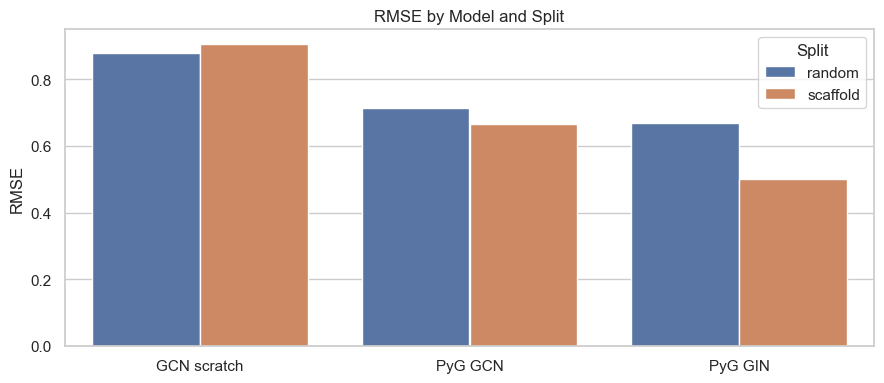

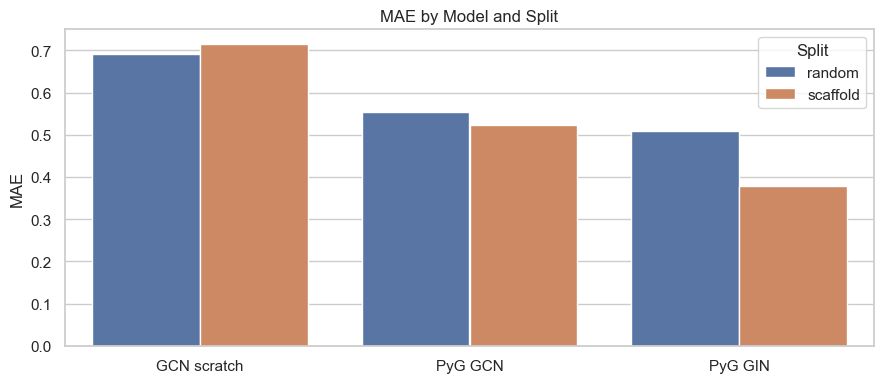

In [9]:
sns.set_theme(style='whitegrid')

plt.figure(figsize=(9, 4))
sns.barplot(data=results_df, x='model', y='rmse', hue='split')
plt.title('RMSE by Model and Split')
plt.ylabel('RMSE')
plt.xlabel('')
plt.legend(title='Split')
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
sns.barplot(data=results_df, x='model', y='mae', hue='split')
plt.title('MAE by Model and Split')
plt.ylabel('MAE')
plt.xlabel('')
plt.legend(title='Split')
plt.tight_layout()
plt.show()

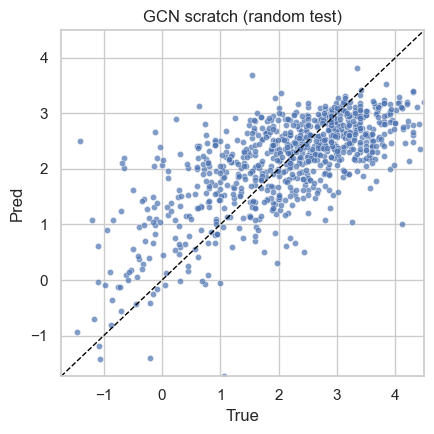

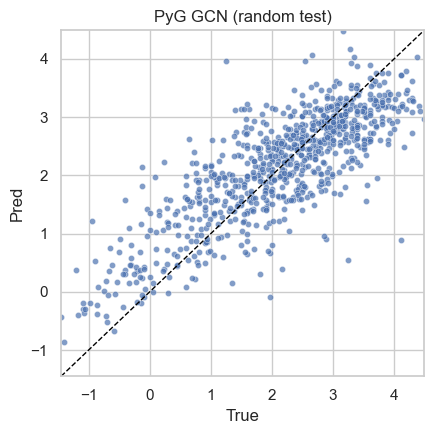

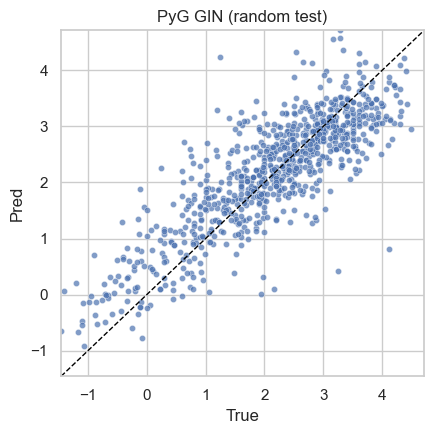

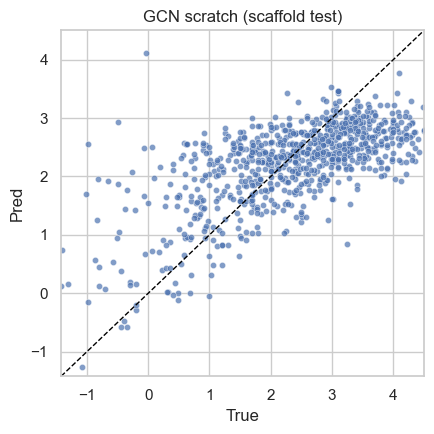

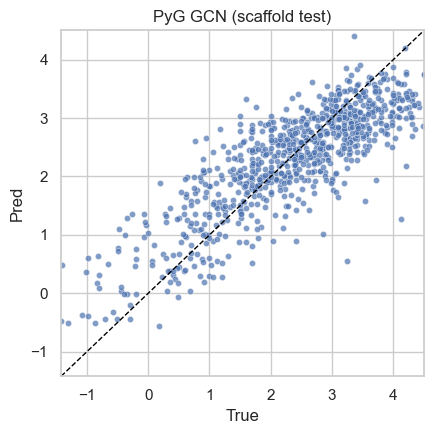

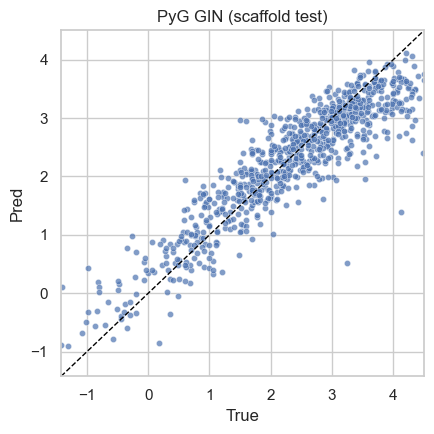

In [10]:
def parity_plot(y_true, y_pred, title):
    plt.figure(figsize=(4.5, 4.5))
    sns.scatterplot(x=y_true, y=y_pred, s=20, alpha=0.7)
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    plt.plot(lims, lims, '--', color='black', linewidth=1)
    plt.xlim(lims)
    plt.ylim(lims)
    plt.xlabel('True')
    plt.ylabel('Pred')
    plt.title(title)
    plt.tight_layout()
    plt.show()

for (split, model), (y_true, y_pred, _) in pred_store.items():
    parity_plot(y_true, y_pred, f'{model} ({split} test)')